In [1]:
# Parameters
ticker = "AAPL"
start_date = "2024-01-01"
end_date = "2024-12-31"
db_path = "data/data.db"

In [2]:
# Parameters
ticker = "IBM"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/davidhuber/Desktop/berkeley prequesites/Preprogram/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/David_MartinsHuber/data/data.db"


# Single-Stock Risk Report

This parameterized report reads validated prices from `ohlc_hw_cleaned` in the homework working database. It uses adjusted close for log returns and drawdown, preserves rolling warm-up gaps, and displays the actual date coverage available for the requested window.

The default example is AAPL for calendar 2024. The local database is not included in the submission; run Part 1 first to create its cleaned table.

In [3]:
from pathlib import Path
import sqlite3

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Normalize user inputs and validate the requested window before querying.
ticker = str(ticker).strip().upper()
if not ticker:
    raise ValueError("ticker must contain a stock symbol.")
start = pd.Timestamp(start_date).normalize()
end = pd.Timestamp(end_date).normalize()
if end < start:
    raise ValueError("end_date must be on or after start_date.")

# Resolve relative paths from the notebook's working directory.
database_path = Path(db_path).expanduser()
if not database_path.is_absolute():
    database_path = (Path.cwd() / database_path).resolve()
if not database_path.is_file():
    raise FileNotFoundError(
        f"Database not found at {database_path}. Run 01_data_cleaning.ipynb first "
        "or pass the path to your local data/data.db working copy."
    )

with sqlite3.connect(f"file:{database_path}?mode=ro", uri=True) as connection:
    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'", connection
    )["name"].tolist()
    if "ohlc_hw_cleaned" not in tables:
        raise RuntimeError(
            f"Table ohlc_hw_cleaned is missing from {database_path}. "
            "Run 01_data_cleaning.ipynb first."
        )
    stock = pd.read_sql_query(
        """SELECT ts, ticker, open, high, low, close, adj_close, volume
           FROM ohlc_hw_cleaned
           WHERE ticker = ? AND ts >= ? AND ts <= ?
           ORDER BY ts""",
        connection,
        params=(ticker, start.strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d")),
    )

if stock.empty:
    raise ValueError(
        f"No cleaned observations found for {ticker} from "
        f"{start.strftime('%Y-%m-%d')} to {end.strftime('%Y-%m-%d')}."
    )

stock["ts"] = pd.to_datetime(stock["ts"], errors="coerce")
stock = stock.dropna(subset=["ts"]).sort_values("ts").set_index("ts")
if stock.index.has_duplicates:
    raise ValueError(f"Cleaned data contains repeated dates for {ticker}.")
prices_array = stock["adj_close"].to_numpy(dtype=float)
if not np.isfinite(prices_array).all() or (prices_array <= 0).any():
    raise ValueError(f"Adjusted closing prices for {ticker} must be finite and positive.")

actual_start = stock.index.min()
actual_end = stock.index.max()
print(
    f"{ticker} from {start.strftime('%Y-%m-%d')} to {end.strftime('%Y-%m-%d')}: "
    f"{len(stock):,} trading days"
)
print(f"Actual observations: {actual_start:%Y-%m-%d} through {actual_end:%Y-%m-%d}")
display(stock.head())
display(stock.tail())

if len(stock) < 21:
    display(Markdown(
        f"**Limited history:** {len(stock)} prices provide fewer than 20 nonmissing "
        "daily returns, so a full 20-return rolling volatility estimate is unavailable. "
        "Available observations and other estimable metrics are still shown."
    ))
if len(stock) < 50:
    display(Markdown(
        f"**50-day moving average:** unavailable for this window because it contains "
        f"only {len(stock)} prices; the chart preserves the warm-up gap."
    ))

IBM from 2024-06-01 to 2024-11-30: 126 trading days
Actual observations: 2024-06-03 through 2024-11-29


,ticker,open,high,low,close,adj_close,volume
ts,,,,,,,
2024-06-03,IBM,166.54,166.78,163.53,165.28,162.57,2776100
2024-06-04,IBM,164.60,166.40,163.88,165.81,163.09,2594203
2024-06-05,IBM,166.41,167.79,165.78,167.38,164.63,3049400
2024-06-06,IBM,167.38,168.44,166.80,168.20,165.44,2207263
2024-06-07,IBM,168.18,171.31,168.06,170.01,167.22,3475500


,ticker,open,high,low,close,adj_close,volume
ts,,,,,,,
2024-11-22,IBM,223.35,227.20,220.89,222.97,222.97,5320740
2024-11-25,IBM,223.35,226.42,222.65,226.13,226.13,7189300
2024-11-26,IBM,226.73,228.98,225.51,228.83,228.83,4449543
2024-11-27,IBM,228.83,229.19,224.27,226.92,226.92,2995121
2024-11-29,IBM,227.75,230.36,227.19,227.41,227.41,2640300


## Risk metric functions

Returns use adjusted close and are daily log returns. Rolling volatility and Sharpe use sample standard deviation (`ddof=1`) and a 252-trading-day annualization.

Historical Value at Risk (VaR) and Expected Shortfall (ES) are added at the 95% confidence level over daily log returns. Both use a positive-loss convention: VaR is the negative 5th-percentile return, and ES is the negative average return in the lower 5% tail. At least 20 nonmissing returns are required for this 5% tail estimate; otherwise the metrics are N/A. The distribution moments use daily log returns: pandas sample skewness and unbiased Fisher excess kurtosis (normal-reference value 0). They display as N/A when fewer than 3 or 4 returns are available, respectively.

In [4]:
def calculate_returns(prices: pd.Series) -> pd.Series:
    """Calculate daily log returns from a positive price series."""
    clean_prices = pd.to_numeric(prices, errors="coerce")
    clean_prices = clean_prices.where(np.isfinite(clean_prices) & clean_prices.gt(0))
    return np.log(clean_prices / clean_prices.shift(1))


def calculate_volatility(returns: pd.Series, window: int = 20) -> pd.Series:
    """Calculate annualized rolling volatility without filling warm-up gaps."""
    if window < 1:
        raise ValueError("window must be a positive integer.")
    valid_returns = returns.replace([np.inf, -np.inf], np.nan)
    return valid_returns.rolling(window=window, min_periods=window).std(ddof=1) * np.sqrt(252)


def calculate_max_drawdown(prices: pd.Series) -> pd.Series:
    """Return the per-date drawdown from the running adjusted-price peak."""
    clean_prices = pd.to_numeric(prices, errors="coerce")
    clean_prices = clean_prices.where(np.isfinite(clean_prices) & clean_prices.gt(0))
    running_peak = clean_prices.cummax()
    return (clean_prices - running_peak) / running_peak


def calculate_sharpe_ratio(returns: pd.Series, risk_free_rate: float = 0.02) -> float:
    """Calculate the annualized course-approximation Sharpe ratio."""
    valid_returns = returns.replace([np.inf, -np.inf], np.nan).dropna()
    if len(valid_returns) < 2:
        return np.nan
    daily_std = valid_returns.std(ddof=1)
    if not np.isfinite(daily_std) or daily_std <= 0:
        return np.nan
    return float((valid_returns.mean() * 252 - risk_free_rate) / (daily_std * np.sqrt(252)))


def calculate_historical_var_es(returns: pd.Series, confidence_level: float = 0.95) -> tuple[float, float]:
    """Return one-day historical VaR and ES as positive-loss fractions.

    VaR is the negative lower-tail quantile; ES is the negative mean of returns
    at or below that quantile. At least 1/(1-confidence_level) observations
    are required so the empirical tail contains at least one return.
    """
    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be strictly between 0 and 1.")
    valid_returns = returns.replace([np.inf, -np.inf], np.nan).dropna()
    minimum_observations = int(np.ceil(1 / (1 - confidence_level)))
    if len(valid_returns) < minimum_observations:
        return np.nan, np.nan
    lower_tail_cutoff = valid_returns.quantile(1 - confidence_level)
    tail_returns = valid_returns.loc[valid_returns.le(lower_tail_cutoff)]
    if tail_returns.empty:
        return np.nan, np.nan
    return float(-lower_tail_cutoff), float(-tail_returns.mean())


adjusted_close = stock["adj_close"].astype(float)
log_returns = calculate_returns(adjusted_close)
rolling_volatility = calculate_volatility(log_returns, window=20)
drawdown = calculate_max_drawdown(adjusted_close)
valid_returns = log_returns.replace([np.inf, -np.inf], np.nan).dropna()
mean_rolling_volatility = rolling_volatility.mean()
sharpe_ratio = calculate_sharpe_ratio(log_returns, risk_free_rate=0.02)
value_at_risk_95, expected_shortfall_95 = calculate_historical_var_es(log_returns, confidence_level=0.95)

print(f"Defined daily log returns: {len(valid_returns):,}")
print(f"Sharpe ratio (2% annual risk-free rate): {sharpe_ratio:.4f}" if np.isfinite(sharpe_ratio) else "Sharpe ratio: N/A (insufficient returns or zero volatility)")
print(f"Mean 20-day rolling annualized volatility: {mean_rolling_volatility:.2%}" if np.isfinite(mean_rolling_volatility) else "Mean rolling volatility: N/A (fewer than 20 nonmissing returns)")
print(f"Maximum drawdown: {drawdown.min():.2%}")
print(f"95% 1-day historical VaR: {value_at_risk_95:.2%}" if np.isfinite(value_at_risk_95) else "95% 1-day historical VaR: N/A")
print(f"95% 1-day expected shortfall: {expected_shortfall_95:.2%}" if np.isfinite(expected_shortfall_95) else "95% 1-day expected shortfall: N/A")

Defined daily log returns: 125
Sharpe ratio (2% annual risk-free rate): 3.2164
Mean 20-day rolling annualized volatility: 19.93%
Maximum drawdown: -12.90%
95% 1-day historical VaR: 1.37%
95% 1-day expected shortfall: 2.66%


## Four-panel risk visualization

Price-line colors use the mean rolling volatility across this report as a retrospective threshold. Segments without a rolling estimate are gray. The 50-day moving average and 20-day volatility retain their warm-up gaps.

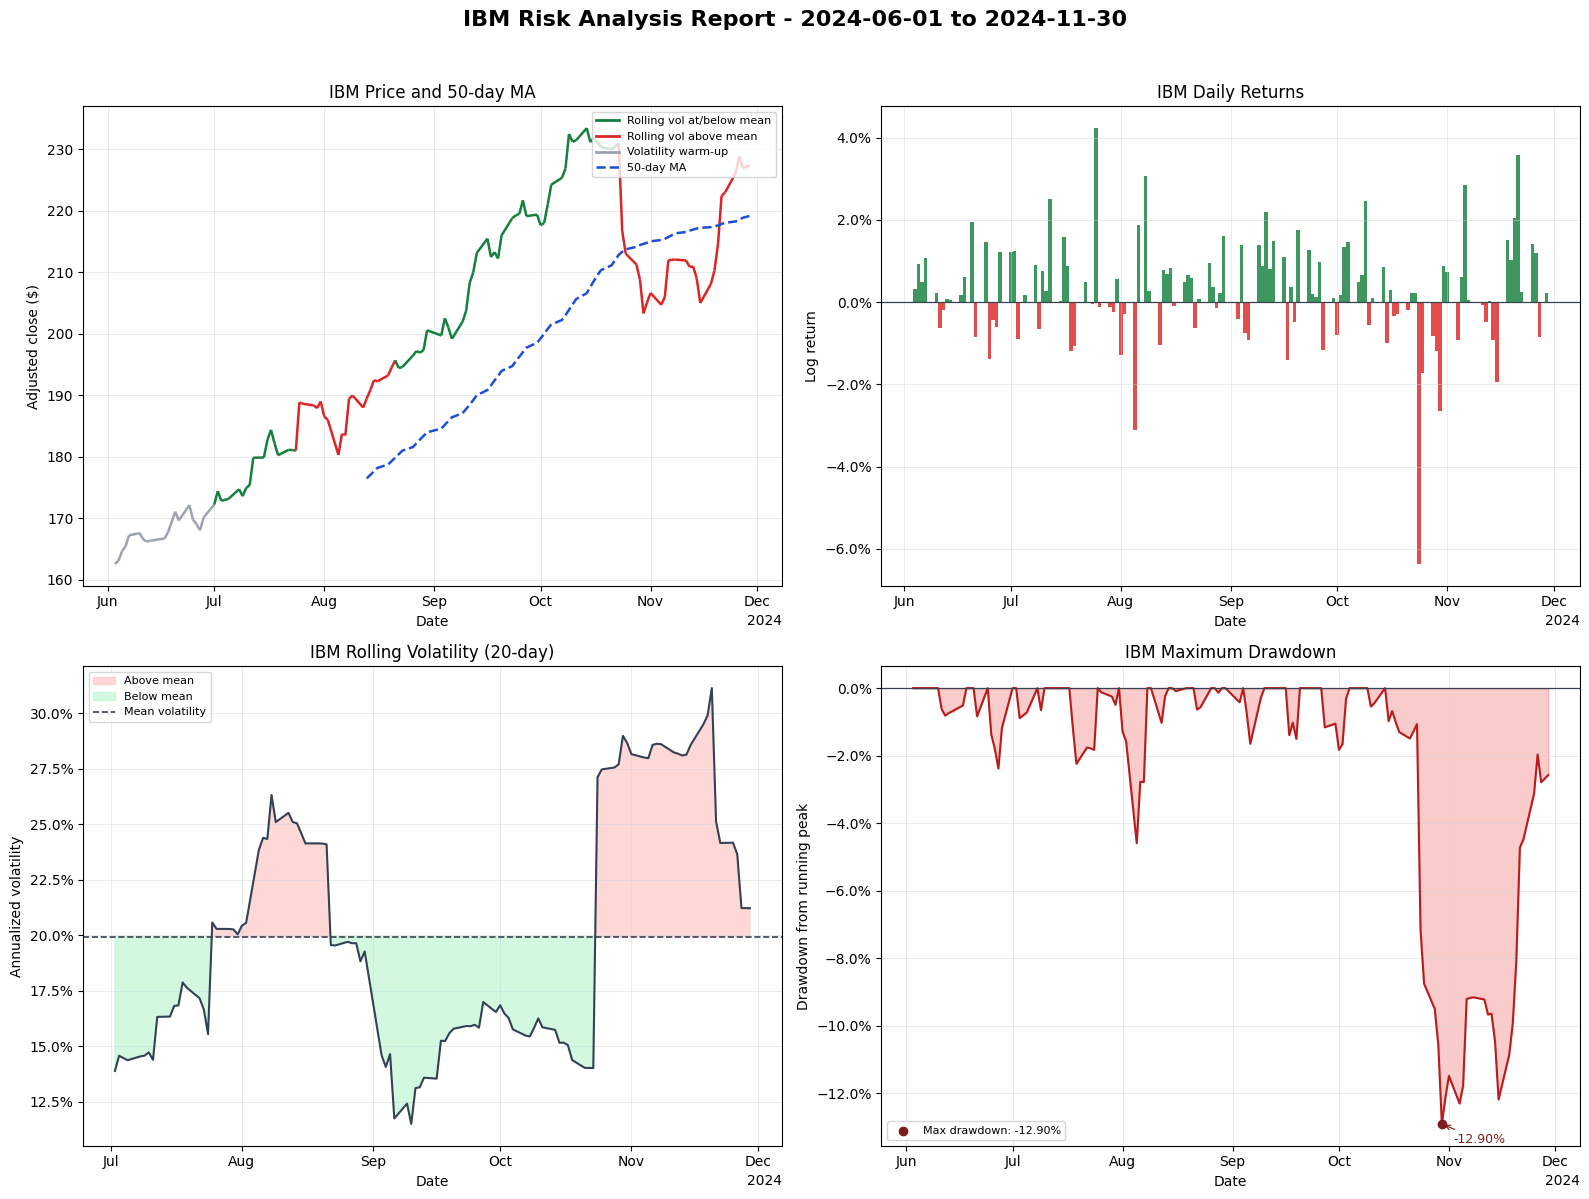

In [5]:
# Price-derived lines and colors.
price_dates = adjusted_close.index
moving_average_50 = adjusted_close.rolling(window=50, min_periods=50).mean()
rolling_mean = rolling_volatility.mean()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_price, ax_returns, ax_volatility, ax_drawdown = axes.ravel()

# Top-left: volatility-colored adjusted-close line and 50-day moving average.
if len(adjusted_close) >= 2:
    x_values = mdates.date2num(price_dates.to_pydatetime())
    y_values = adjusted_close.to_numpy(dtype=float)
    points = np.column_stack([x_values, y_values]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    endpoint_volatility = rolling_volatility.to_numpy(dtype=float)[1:]
    segment_colors = [
        "#9ca3af" if not np.isfinite(value)
        else "#dc2626" if np.isfinite(rolling_mean) and value > rolling_mean
        else "#15803d"
        for value in endpoint_volatility
    ]
    price_line = LineCollection(segments, colors=segment_colors, linewidths=1.8)
    ax_price.add_collection(price_line)
    ax_price.autoscale_view()
else:
    ax_price.scatter(price_dates, adjusted_close, color="#15803d", s=24, zorder=3)
ax_price.plot(price_dates, moving_average_50, color="#1d4ed8", linewidth=1.8, linestyle="--", label="50-day MA")
ax_price.set_title(f"{ticker} Price and 50-day MA")
ax_price.set_ylabel("Adjusted close ($)")
ax_price.set_xlabel("Date")
ax_price.legend(handles=[
    Line2D([0], [0], color="#15803d", lw=2, label="Rolling vol at/below mean"),
    Line2D([0], [0], color="#dc2626", lw=2, label="Rolling vol above mean"),
    Line2D([0], [0], color="#9ca3af", lw=2, label="Volatility warm-up"),
    Line2D([0], [0], color="#1d4ed8", lw=1.8, ls="--", label="50-day MA"),
], loc="best", fontsize=8)

# Top-right: daily log returns.
return_colors = np.where(valid_returns.gt(0), "#15803d", np.where(valid_returns.lt(0), "#dc2626", "#6b7280"))
ax_returns.bar(valid_returns.index, valid_returns.to_numpy(), color=return_colors, width=1.0, alpha=0.82)
ax_returns.axhline(0, color="#374151", linewidth=0.9)
ax_returns.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_returns.set_title(f"{ticker} Daily Returns")
ax_returns.set_ylabel("Log return")
ax_returns.set_xlabel("Date")

# Bottom-left: rolling volatility and high/low regions around its mean.
vol_values = rolling_volatility.to_numpy(dtype=float)
if np.isfinite(rolling_mean):
    high_vol = rolling_volatility.gt(rolling_mean)
    low_vol = rolling_volatility.lt(rolling_mean)
    ax_volatility.fill_between(rolling_volatility.index, rolling_mean, vol_values, where=high_vol.to_numpy(), color="#fecaca", alpha=0.75, interpolate=True, label="Above mean")
    ax_volatility.fill_between(rolling_volatility.index, rolling_mean, vol_values, where=low_vol.to_numpy(), color="#bbf7d0", alpha=0.65, interpolate=True, label="Below mean")
    ax_volatility.axhline(rolling_mean, color="#374151", linestyle="--", linewidth=1.2, label="Mean volatility")
ax_volatility.plot(rolling_volatility.index, rolling_volatility, color="#334155", linewidth=1.5)
ax_volatility.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_volatility.set_title(f"{ticker} Rolling Volatility (20-day)")
ax_volatility.set_ylabel("Annualized volatility")
ax_volatility.set_xlabel("Date")
if np.isfinite(rolling_mean):
    ax_volatility.legend(loc="best", fontsize=8)

# Bottom-right: drawdown with layered red fills and the worst point.
drawdown_values = drawdown.to_numpy(dtype=float)
for layer, alpha in enumerate([0.08, 0.07, 0.06, 0.05, 0.04]):
    ax_drawdown.fill_between(drawdown.index, drawdown_values, 0, where=drawdown_values <= 0, color="#ef4444", alpha=alpha, interpolate=True)
ax_drawdown.plot(drawdown.index, drawdown, color="#b91c1c", linewidth=1.5)
ax_drawdown.axhline(0, color="#374151", linewidth=0.9)
if drawdown.notna().any():
    worst_date = drawdown.idxmin()
    worst_value = float(drawdown.loc[worst_date])
    ax_drawdown.scatter([worst_date], [worst_value], color="#7f1d1d", zorder=4, label=f"Max drawdown: {worst_value:.2%}")
    ax_drawdown.annotate(
        f"{worst_value:.2%}", xy=(worst_date, worst_value), xytext=(8, -14),
        textcoords="offset points", color="#7f1d1d", fontsize=9,
        arrowprops={"arrowstyle": "->", "color": "#7f1d1d", "lw": 0.8},
    )
    ax_drawdown.legend(loc="best", fontsize=8)
ax_drawdown.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax_drawdown.set_title(f"{ticker} Maximum Drawdown")
ax_drawdown.set_ylabel("Drawdown from running peak")
ax_drawdown.set_xlabel("Date")

for ax in axes.ravel():
    ax.grid(True, color="#cbd5e1", alpha=0.45, linewidth=0.7)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(ax.xaxis.get_major_locator()))

fig.suptitle(
    f"{ticker} Risk Analysis Report - {start.strftime('%Y-%m-%d')} to {end.strftime('%Y-%m-%d')}",
    fontsize=16, fontweight="bold", y=0.995,
)
fig.tight_layout(rect=[0, 0, 1, 0.975])
plt.show()

## Summary statistics

Percentages below are formatted for display. The `report_metrics` dictionary retains fractional values so Part 3 can collect the results without parsing the table.

In [6]:
def finite_or_nan(value) -> float:
    """Convert a scalar to a finite float or NaN when it is undefined."""
    try:
        number = float(value)
    except (TypeError, ValueError):
        return np.nan
    return number if np.isfinite(number) else np.nan


def display_percent(value, signed: bool = False) -> str:
    """Format a fractional metric as a percentage, or N/A if undefined."""
    number = finite_or_nan(value)
    if not np.isfinite(number):
        return "N/A"
    return f"{number:+.2%}" if signed else f"{number:.2%}"


def calculate_return_moments(returns: pd.Series) -> tuple[float, float]:
    """Calculate sample skewness and unbiased Fisher excess kurtosis.

    Skewness needs at least three valid returns; kurtosis needs at least four.
    Pandas returns excess kurtosis, whose normal-reference value is zero.
    """
    valid = returns.replace([np.inf, -np.inf], np.nan).dropna()
    skewness = float(valid.skew()) if len(valid) >= 3 else np.nan
    excess_kurtosis = float(valid.kurt()) if len(valid) >= 4 else np.nan
    return skewness, excess_kurtosis


return_count = len(valid_returns)
return_skewness, return_excess_kurtosis = calculate_return_moments(valid_returns)
if return_count:
    total_return = float(adjusted_close.iloc[-1] / adjusted_close.iloc[0] - 1)
    annualized_return = float(np.exp(valid_returns.sum() * 252 / return_count) - 1)
    best_day = float(valid_returns.max())
    worst_day = float(valid_returns.min())
    positive_days = float(valid_returns.gt(0).sum() / return_count)
    up_returns = valid_returns.loc[valid_returns.gt(0)]
    down_returns = valid_returns.loc[valid_returns.lt(0)]
    average_up_day = float(up_returns.mean()) if not up_returns.empty else np.nan
    average_down_day = float(down_returns.mean()) if not down_returns.empty else np.nan
else:
    total_return = np.nan  # One price has no defined period return.
    annualized_return = best_day = worst_day = positive_days = np.nan
    average_up_day = average_down_day = np.nan

annualized_volatility = float(valid_returns.std(ddof=1) * np.sqrt(252)) if return_count >= 2 else np.nan
maximum_drawdown = float(drawdown.min()) if drawdown.notna().any() else np.nan

summary_rows = [
    ("Total Return", display_percent(total_return, signed=True)),
    ("Annualized Return", display_percent(annualized_return, signed=True)),
    ("Annualized Volatility", display_percent(annualized_volatility)),
    ("Sharpe Ratio", f"{sharpe_ratio:.2f}" if np.isfinite(sharpe_ratio) else "N/A"),
    ("95% 1-day Historical VaR", display_percent(value_at_risk_95)),
    ("95% 1-day Expected Shortfall", display_percent(expected_shortfall_95)),
    ("Daily Return Skewness", f"{return_skewness:.2f}" if np.isfinite(return_skewness) else "N/A"),
    ("Daily Return Excess Kurtosis", f"{return_excess_kurtosis:.2f}" if np.isfinite(return_excess_kurtosis) else "N/A"),
    ("Maximum Drawdown", display_percent(maximum_drawdown, signed=True)),
    ("Best Day", display_percent(best_day, signed=True)),
    ("Worst Day", display_percent(worst_day, signed=True)),
    ("Positive Days", display_percent(positive_days)),
    ("Average Up Day", display_percent(average_up_day, signed=True)),
    ("Average Down Day", display_percent(average_down_day, signed=True)),
]
summary_table = pd.DataFrame(summary_rows, columns=["Metric", "Value"])
display(summary_table.style.hide(axis="index").set_properties(**{"text-align": "left"}).set_table_styles([
    {"selector": "th", "props": [("background-color", "#e2e8f0"), ("color", "#0f172a"), ("font-weight", "bold")]},
    {"selector": "td", "props": [("padding", "6px 14px")]},
]))

# Numeric fractional metrics for the future all-stock runner.
report_metrics = {
    "ticker": ticker,
    "requested_start_date": start.strftime("%Y-%m-%d"),
    "requested_end_date": end.strftime("%Y-%m-%d"),
    "actual_start_date": actual_start.strftime("%Y-%m-%d"),
    "actual_end_date": actual_end.strftime("%Y-%m-%d"),
    "trading_days": int(len(stock)),
    "avg_daily_return": finite_or_nan(valid_returns.mean()),
    "avg_volatility": finite_or_nan(rolling_volatility.mean()),
    "max_drawdown": finite_or_nan(maximum_drawdown),
    "sharpe_ratio": finite_or_nan(sharpe_ratio),
    "value_at_risk_95_1d": finite_or_nan(value_at_risk_95),
    "expected_shortfall_95_1d": finite_or_nan(expected_shortfall_95),
    "return_skewness": finite_or_nan(return_skewness),
    "return_excess_kurtosis": finite_or_nan(return_excess_kurtosis),
    "total_return": finite_or_nan(total_return),
    "annualized_return": finite_or_nan(annualized_return),
    "annualized_volatility": finite_or_nan(annualized_volatility),
    "best_day": finite_or_nan(best_day),
    "worst_day": finite_or_nan(worst_day),
    "positive_days": finite_or_nan(positive_days),
    "average_up_day": finite_or_nan(average_up_day),
    "average_down_day": finite_or_nan(average_down_day),
}
# Keep machine-readable metrics in a standard, visually empty notebook output.
# The batch runner reads this named output from each successfully executed report.
display({"text/plain": ""}, metadata={"hw2_report_metrics": report_metrics}, raw=True)

Metric,Value
Total Return,+39.88%
Annualized Return,+96.73%
Annualized Volatility,20.42%
Sharpe Ratio,3.22
95% 1-day Historical VaR,1.37%
95% 1-day Expected Shortfall,2.66%
Daily Return Skewness,-0.81
Daily Return Excess Kurtosis,5.72
Maximum Drawdown,-12.90%
Best Day,+4.24%
